# 03 · Perceptrón multicapa (MLP) clasificador

Formulación: h(x) = softmax(W₂σ(W₁x+b₁)+b₂). Entropía cruzada + L2, backpropagation. Búsqueda aleatoria de hiperparámetros, métricas y calibración, experimentos E1-E4, y comprobación de gradientes por diferencias finitas sobre la implementación en NumPy.

In [1]:
import sys
sys.path.insert(0, "../src")
import numpy as np
import matplotlib.pyplot as plt
from familia3 import SEED
np.random.seed(SEED)
%matplotlib inline


In [2]:
from familia3 import datos as D
from familia3.pipelines import pipeline_mlp
from familia3.busqueda import buscar_mlp
from familia3.metricas import metricas_clasificacion
from familia3 import graficos as G

cancer = D.cargar_breast_cancer()
moons = D.sintetico_moons()


## Búsqueda aleatoria de hiperparámetros

In [3]:
busqueda = buscar_mlp(cancer.X_train, cancer.y_train, n_iter=20)
print("mejores hiperparámetros:", busqueda.best_params_)
print("roc_auc (cv):", round(busqueda.best_score_, 4))
modelo = busqueda.best_estimator_


mejores hiperparámetros: {'clf__solver': 'adam', 'clf__learning_rate_init': np.float64(0.046415888336127774), 'clf__hidden_layer_sizes': (32, 32, 16), 'clf__alpha': np.float64(0.00021544346900318823), 'clf__activation': 'tanh'}
roc_auc (cv): 0.9947


## Métricas sobre prueba

In [4]:
y_pred = modelo.predict(cancer.X_test)
y_proba = modelo.predict_proba(cancer.X_test)
m = metricas_clasificacion(cancer.y_test, y_pred, y_proba)
for k, v in m.items():
    print(f"{k:12s}: {v:.4f}")


precision   : 0.9855
recall      : 0.9444
f1          : 0.9645
roc_auc     : 0.9947
log_loss    : 0.1303
brier       : 0.0337


## Curva de pérdida de entrenamiento

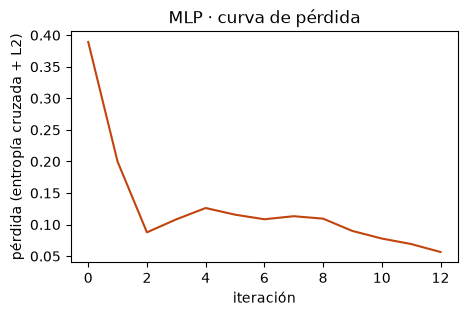

In [5]:
fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(modelo.named_steps["clf"].loss_curve_, color="#c1440e")
ax.set_xlabel("iteración"); ax.set_ylabel("pérdida (entropía cruzada + L2)")
ax.set_title("MLP · curva de pérdida")
plt.savefig("../reports/figuras/03_mlp_perdida.png", dpi=150, bbox_inches="tight")
plt.show()


## Frontera 2D y calibración

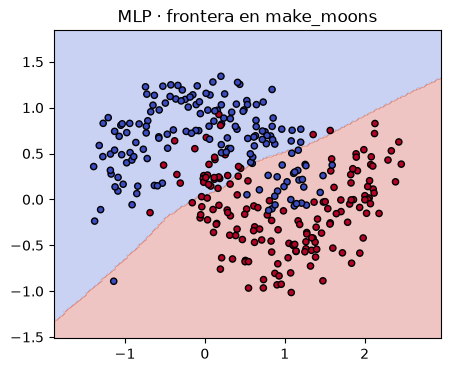

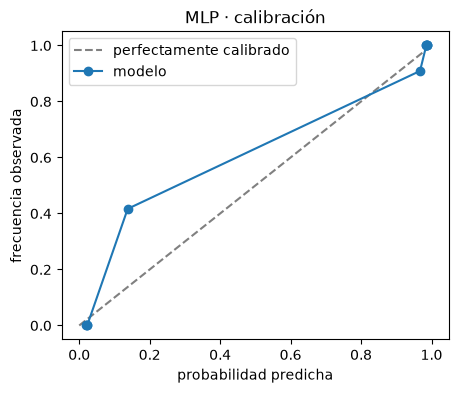

In [6]:
modelo_moons = pipeline_mlp(hidden_layer_sizes=(32, 16)).fit(moons.X_train, moons.y_train)
G.frontera_decision(modelo_moons, moons.X_train, moons.y_train, "03_mlp_frontera_moons.png", "MLP · frontera en make_moons")
plt.show()
G.curva_calibracion_manual(cancer.y_test, y_proba[:, 1], "03_mlp_calibracion.png", "MLP · calibración")
plt.show()


## Experimentos E1-E4: regularización, parada temprana, profundidad

In [7]:
from sklearn.metrics import roc_auc_score

experimentos = {
    "E1 sin regularización (alpha~0)": pipeline_mlp(alpha=1e-10, early_stopping=False, hidden_layer_sizes=(64, 32)),
    "E2 con regularización (alpha=1e-2)": pipeline_mlp(alpha=1e-2, early_stopping=False, hidden_layer_sizes=(64, 32)),
    "E3 con parada temprana": pipeline_mlp(alpha=1e-4, early_stopping=True, hidden_layer_sizes=(64, 32)),
    "E4 más profunda": pipeline_mlp(alpha=1e-4, early_stopping=True, hidden_layer_sizes=(64, 32, 16)),
}
for nombre, exp in experimentos.items():
    exp.fit(cancer.X_train, cancer.y_train)
    auc_train = roc_auc_score(cancer.y_train, exp.predict_proba(cancer.X_train)[:, 1])
    auc_test = roc_auc_score(cancer.y_test, exp.predict_proba(cancer.X_test)[:, 1])
    print(f"{nombre:32s} roc_auc train={auc_train:.4f}  test={auc_test:.4f}  brecha={auc_train - auc_test:.4f}")


E1 sin regularización (alpha~0)  roc_auc train=1.0000  test=0.9940  brecha=0.0060


E2 con regularización (alpha=1e-2) roc_auc train=1.0000  test=0.9937  brecha=0.0063
E3 con parada temprana           roc_auc train=0.9909  test=0.9927  brecha=-0.0019
E4 más profunda                  roc_auc train=0.9920  test=0.9914  brecha=0.0006


## Estabilidad con 10 semillas

In [8]:
aucs = []
for s in range(10):
    m = pipeline_mlp(seed=s).fit(cancer.X_train, cancer.y_train)
    aucs.append(roc_auc_score(cancer.y_test, m.predict_proba(cancer.X_test)[:, 1]))
print(f"roc_auc en 10 semillas: media={np.mean(aucs):.4f}  desviación={np.std(aucs):.4f}")


roc_auc en 10 semillas: media=0.9845  desviación=0.0104


## Verificación matemática: comprobación de gradientes (diferencias finitas)

In [9]:
from familia3.desde_cero import MLPNumPy, comprobar_gradientes

rng = np.random.default_rng(0)
X_peq = rng.normal(size=(20, 4))
y_peq = rng.integers(0, 3, size=20)
red_pequena = MLPNumPy(n_entradas=4, n_ocultas=5, n_clases=3, alpha=1e-3, seed=0)
error_relativo = comprobar_gradientes(red_pequena, X_peq, y_peq)
print("error relativo gradiente analítico vs numérico:", error_relativo)
assert error_relativo < 1e-4
print("Verificado: backpropagation coincide con diferencias finitas.")


error relativo gradiente analítico vs numérico: 4.702535284520201e-11
Verificado: backpropagation coincide con diferencias finitas.


## Comparación con `MLPClassifier` en un problema pequeño

In [10]:
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler

Xs = StandardScaler().fit_transform(cancer.X_train[:, :6])
red = MLPNumPy(n_entradas=6, n_ocultas=10, n_clases=2, alpha=1e-4, seed=0)
red.fit(Xs, cancer.y_train, epocas=800, tasa_aprendizaje=1.0)
ref = MLPClassifier(hidden_layer_sizes=(10,), activation="logistic", alpha=1e-4, max_iter=800, random_state=0).fit(Xs, cancer.y_train)

pred_propio = red.predict(Xs)
pred_ref = ref.predict(Xs)
acuerdo = np.mean(pred_propio == pred_ref)
print(f"acuerdo de predicciones NumPy vs MLPClassifier (mismo problema): {acuerdo:.2%}")


acuerdo de predicciones NumPy vs MLPClassifier (mismo problema): 97.14%
